# Preprocessing — Amazon Product Dataset 2020

Covers task backlog §1.2 "Preprocessing", building on the findings from
[1.1 explore data.ipynb](1.1%20explore%20data.ipynb) (§1.1):

- clean text fields (strip HTML, normalize whitespace/encoding)
- extract brand from title text (`Brand Name` is 100% empty — see §1.1)
- normalize units where package size is parseable (price per oz/ct/etc.)
- deduplicate near-identical listings (no `Asin`/`Sku` key exists — dedupe by title)
- flatten the pipe-delimited `Category` hierarchy
- persist `products_clean.csv`

Self-contained (no separate `.py` script) and pre-executed. CSV in, CSV out — no
parquet, per project convention.

In [1]:
# !pip install pandas matplotlib numpy

## Setup

In [2]:
import html
import os
import re
import unicodedata
import sys

import pandas as pd

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
CSV_PATH = os.path.join(
    REPO_ROOT, "Data", "sdf",
    "marketing_sample_for_amazon_com-ecommerce__20200101_20200131__10k_data.csv",
)
OUTPUT_DIR = os.path.join(os.getcwd(), "processed")
OUTPUT_CSV = os.path.join(OUTPUT_DIR, "products_clean.csv")

TEXT_COLUMNS = ["Product Name", "About Product", "Technical Details", "Product Specification"]

if not os.path.exists(CSV_PATH):
    sys.exit(f"Could not find the dataset at:\n  {CSV_PATH}")

df = pd.read_csv(CSV_PATH)
n_start = len(df)
print(f"Loaded {n_start:,} rows.")
df.head(3)

Loaded 10,002 rows.


,Uniq Id,Product Name,Brand Name,Asin,Category,Upc Ean Code,List Price,Selling Price,Quantity,Model Number,...,Product Url,Stock,Product Details,Dimensions,Color,Ingredients,Direction To Use,Is Amazon Seller,Size Quantity Variant,Product Description
0,4c69b61db1fc16e7013b43fc926e502d,"DB Longboards CoreFlex Crossbow 41"" Bamboo Fib...",NaN,NaN,Sports & Outdoors | Outdoor Recreation | Skate...,NaN,NaN,$237.68,NaN,NaN,...,https://www.amazon.com/DB-Longboards-CoreFlex-...,NaN,NaN,NaN,NaN,NaN,NaN,Y,NaN,NaN
1,66d49bbed043f5be260fa9f7fbff5957,"Electronic Snap Circuits Mini Kits Classpack, ...",NaN,NaN,Toys & Games | Learning & Education | Science ...,NaN,NaN,$99.95,NaN,55324,...,https://www.amazon.com/Electronic-Circuits-Cla...,NaN,NaN,NaN,NaN,NaN,NaN,Y,NaN,NaN
2,2c55cae269aebf53838484b0d7dd931a,3Doodler Create Flexy 3D Printing Filament Ref...,NaN,NaN,Toys & Games | Arts & Crafts | Craft Kits,NaN,NaN,$34.99,NaN,NaN,...,https://www.amazon.com/3Doodler-Plastic-Innova...,NaN,NaN,NaN,NaN,NaN,NaN,Y,NaN,NaN


In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

# Palette (project data-viz skill default): same roles as 1.1 explore data.ipynb.
BLUE = "#2a78d6"
ORANGE = "#eb6834"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID = "#e5e4df"


def clean_ax(ax, x_grid=True, y_grid=False):
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(TEXT_SECONDARY)
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=9)
    ax.xaxis.label.set_color(TEXT_SECONDARY)
    ax.yaxis.label.set_color(TEXT_SECONDARY)
    if x_grid:
        ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
    if y_grid:
        ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

## 1. Text cleaning

Strip HTML, unescape entities, normalize unicode (curly quotes etc.), collapse whitespace.

In [4]:
def clean_text(value):
    if pd.isna(value):
        return value
    text = str(value)
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text if text else pd.NA


for col in TEXT_COLUMNS:
    df[col] = df[col].apply(clean_text)

print("Cleaned:", TEXT_COLUMNS)

Cleaned: ['Product Name', 'About Product', 'Technical Details', 'Product Specification']


## 2. Brand extraction (heuristic)

`Brand Name` is 100% empty in this dataset (§1.1), so there's **no ground truth to
validate against** — this is a low-confidence signal, not authoritative:

1. `"<Product Line> by <Brand>"` — an explicit marker, checked first (e.g. *"Terra
   by Battat"* → `Battat`).
2. Otherwise, the leading run of capitalized tokens, **capped at 2 words**. Amazon
   titles are title-cased throughout — every word capitalized, not just the brand
   — so a longer run just captures part of the product name too.

In [5]:
BRAND_STOP_WORDS = {
    "with", "for", "the", "and", "by", "a", "an", "of", "to", "in", "on",
    "set", "pack", "kit", "inch", "inches",
}
MAX_BRAND_WORDS = 2
BRAND_BY_PATTERN = re.compile(r"\bby\s+([A-Z][\w&'.-]*(?:\s+[A-Z][\w&'.-]*){0,2})")


def extract_brand(title):
    if pd.isna(title):
        return pd.NA
    text = str(title)

    by_match = BRAND_BY_PATTERN.search(text)
    if by_match:
        return by_match.group(1).strip()

    tokens = text.split()
    brand_tokens = []
    for tok in tokens[:MAX_BRAND_WORDS]:
        bare = tok.strip(".,-\"'()")
        if not bare or bare.lower() in BRAND_STOP_WORDS or bare[0].isdigit() or not bare[0].isupper():
            break
        brand_tokens.append(bare)
    return " ".join(brand_tokens) if brand_tokens else pd.NA


df["brand"] = df["Product Name"].apply(extract_brand)
brand_coverage = df["brand"].notna().mean()
print(f"Extracted a brand candidate for {brand_coverage:.1%} of rows.")

Extracted a brand candidate for 96.1% of rows.


**Chart:** which rule produced each brand candidate. The explicit `"by <Brand>"`
marker (orange) is materially more trustworthy than the leading-word-run fallback
(blue) — this breakdown is what the honest quality check above is actually
weighing.

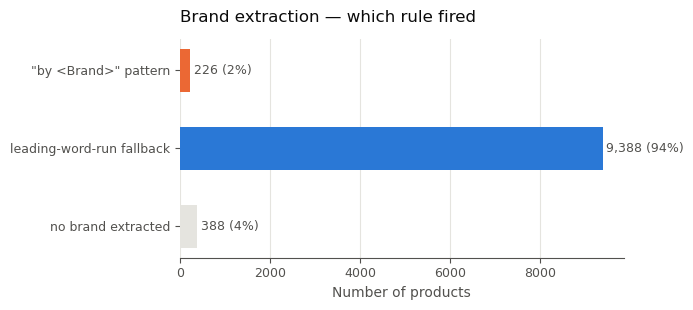

In [6]:
# Reclassify (for charting only) which rule fired for each row — doesn't change
# the `brand` column already computed above, just labels its provenance.
def brand_method(title):
    if pd.isna(title):
        return "no title"
    if BRAND_BY_PATTERN.search(str(title)):
        return '"by <Brand>" pattern'
    if pd.notna(extract_brand(title)):
        return "leading-word-run fallback"
    return "no brand extracted"


method_counts = df["Product Name"].apply(brand_method).value_counts()
order = ['"by <Brand>" pattern', "leading-word-run fallback", "no brand extracted"]
method_counts = method_counts.reindex(order).fillna(0)
colors = [ORANGE, BLUE, GRID]

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(method_counts.index[::-1], method_counts.values[::-1],
                color=colors[::-1], height=0.55, zorder=3)
ax.set_xlabel("Number of products")
ax.set_title("Brand extraction — which rule fired", color=TEXT_PRIMARY,
             fontsize=12, loc="left", pad=12)
clean_ax(ax)
for bar, val in zip(bars, method_counts.values[::-1]):
    ax.text(bar.get_width() + 80, bar.get_y() + bar.get_height() / 2,
            f"{int(val):,} ({val / len(df):.0%})", va="center", fontsize=9,
            color=TEXT_SECONDARY)

plt.tight_layout()
plt.show()

**Honest quality check** — coverage (a value was extracted) is not the same as
accuracy (the value is right). A random sample, reviewed by hand:

In [7]:
sample = df[["Product Name", "brand"]].dropna(subset=["brand"]).sample(n=12, random_state=0)
for _, row in sample.iterrows():
    print(f"  '{row['brand']}'  <-  {row['Product Name'][:65]}")

  'Sassy Fishy'  <-  Sassy Fishy Fascination Station 2-in-1 Suction Cup High Chair Toy
  'WWE Wrestlemania'  <-  WWE Wrestlemania Elite Kevin Owens Figure
  'Lunchskins Reusable'  <-  Lunchskins Reusable 2 Piece Food Storage Bag Set, 1 Sandwich Bag 
  'Proline'  <-  Proline 624903 Trifecta Black Wing for 1/8 Buggy Or Truck
  'American Greetings'  <-  American Greetings, My Little Pony Party Tiaras, 8-Count
  'MightySkins Skin'  <-  MightySkins Skin Compatible with Swagtron T5 Hover Board – Deco F
  'Balloon Fisher'  <-  Balloon Fisher King 400 Multi-Clip Pro Pack
  'Triple Eight'  <-  Triple Eight Sweatsaver Liner Skateboarding Helmet, All Black Rub
  'Ever After'  <-  Ever After High Dragon Games Child's Holly O'Hair Wig
  'Redcat Racing'  <-  Redcat Racing RER11413 Aluminum Transfer Case Drive Shaft, Silver
  'Ty Rainbow'  <-  Ty Rainbow - Slipper Socks lrg
  'Magformers Pentagon'  <-  Magformers Pentagon 12 Pieces Rainbow Colors, Educational Magneti


Reviewing this sample (and others at different random seeds): roughly **5/12 are
exact matches** (`Proline`, `American Greetings`, `Triple Eight`, `Redcat Racing`,
`Sassy Fishy`), **~5/12 get the correct leading word but append one extra token**
from the product line (`Lunchskins Reusable` → real brand is just `Lunchskins`;
`MightySkins Skin`, `Ty Rainbow`, `Magformers Pentagon`, `WWE Wrestlemania` are the
same pattern) — still usable for coarse grouping/search-boosting since the real
brand is a prefix, and **~2/12 are undercaptured or wrong** (`Ever After` should be
`Ever After High`; `Balloon Fisher` is ambiguous even to a human reader).

**Bottom line:** treat `brand` as a coarse, low-confidence field — good enough for
"does this look like the same brand" grouping, not for making a brand claim in a
cited answer. If brand precision matters downstream (e.g. a user asks specifically
for a brand), extracting it with an LLM at query/index time, or sourcing a second
dataset that actually has `Brand Name` populated, will do meaningfully better than
this regex.

That 5/12-exact split roughly tracks the method breakdown charted above: only **2% of rows matched the higher-confidence "by <Brand>" pattern**; the other 94% came from the weaker leading-word-run fallback, which is exactly where the noisy cases concentrate.

## 3. Price parsing + unit normalization

`Selling Price` (not `List Price`, which is 0% populated — see §1.1) is parsed to a
clean number. Where a package-size mention (e.g. "16 oz", "2 pack") appears in the
title, price-per-unit is computed for fairer comparison across pack sizes.

In [8]:
UNIT_PATTERN = re.compile(
    r"(\d+(?:\.\d+)?)\s?"
    r"(fl\.?\s?oz|fluid ounces?|ounces?|oz\b|ml\b|milliliters?|liters?|litres?|\bl\b|"
    r"pounds?|lbs?\b|kilograms?|kg\b|grams?|\bg\b|count\b|\bct\b|pack\b|\bpk\b|pieces?|\bpcs\b)",
    re.IGNORECASE,
)
UNIT_CANON = {
    "oz": "oz", "ounce": "oz", "ounces": "oz", "fl oz": "oz", "fl.oz": "oz",
    "fluid ounce": "oz", "fluid ounces": "oz",
    "ml": "ml", "milliliter": "ml", "milliliters": "ml",
    "l": "l", "liter": "l", "liters": "l", "litre": "l", "litres": "l",
    "lb": "lb", "lbs": "lb", "pound": "lb", "pounds": "lb",
    "kg": "kg", "kilogram": "kg", "kilograms": "kg",
    "g": "g", "gram": "g", "grams": "g",
    "count": "ct", "ct": "ct", "pack": "ct", "pk": "ct",
    "piece": "ct", "pieces": "ct", "pcs": "ct",
}


def parse_price(series):
    return pd.to_numeric(
        series.astype(str).str.replace(r"[^0-9.]", "", regex=True), errors="coerce"
    )


def extract_unit_price(title, price):
    if pd.isna(title) or pd.isna(price):
        return pd.NA, pd.NA
    match = UNIT_PATTERN.search(str(title))
    if not match:
        return pd.NA, pd.NA
    qty = float(match.group(1))
    unit = UNIT_CANON.get(match.group(2).lower().replace(".", "").strip())
    if not unit or qty <= 0:
        return pd.NA, pd.NA
    return round(price / qty, 4), unit


df["price"] = parse_price(df["Selling Price"])
print(f"Parsed a numeric price for {df['price'].notna().mean():.1%} of rows.")

unit_results = df.apply(lambda r: extract_unit_price(r["Product Name"], r["price"]), axis=1)
df["price_per_unit"] = unit_results.apply(lambda t: t[0])
df["price_unit"] = unit_results.apply(lambda t: t[1])
print(f"Found a parseable package size in {df['price_unit'].notna().mean():.1%} of rows.")

Parsed a numeric price for 95.2% of rows.
Found a parseable package size in 9.7% of rows.


**Chart:** of the ~10% of rows where a package size was parseable, which units
show up, and what price-per-unit looks like once normalized.

**Caveat:** the right-hand histogram pools every unit family (oz, ml, lb, kg, g, ct)
into one log-scale view — it is a rough overall picture, not an apples-to-apples
comparison. A real per-unit price comparison for the app should filter to one unit
family at a time (e.g. compare cleaners in $/oz against other $/oz listings only).

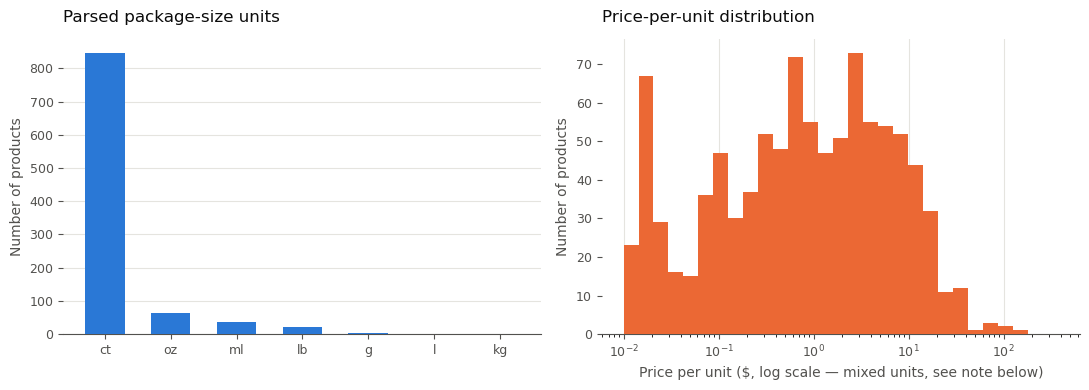

In [9]:
unit_counts = df["price_unit"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.bar(unit_counts.index, unit_counts.values, color=BLUE, width=0.6, zorder=3)
ax.set_ylabel("Number of products")
ax.set_title("Parsed package-size units", color=TEXT_PRIMARY, fontsize=12,
             loc="left", pad=12)
clean_ax(ax, x_grid=False, y_grid=True)

ax = axes[1]
ppu = df["price_per_unit"].dropna()
import numpy as np
bins = np.logspace(np.log10(max(ppu.min(), 0.01)), np.log10(ppu.max()), 30)
ax.hist(ppu, bins=bins, color=ORANGE, zorder=3)
ax.set_xscale("log")
ax.set_xlabel("Price per unit ($, log scale — mixed units, see note below)")
ax.set_ylabel("Number of products")
ax.set_title("Price-per-unit distribution", color=TEXT_PRIMARY, fontsize=12,
             loc="left", pad=12)
clean_ax(ax)

plt.tight_layout()
plt.show()

## 4. Deduplication

No `Asin`/`Sku` key exists (both 100% empty — §1.1), so dedupe on exact `Product
Name` match instead (137 duplicate titles were found in exploration; some collapse
into fewer duplicate groups once cleaned).

In [10]:
before = len(df)
df = df.drop_duplicates(subset=["Product Name"], keep="first")
print(f"Removed {before - len(df)} duplicate-title rows ({before:,} -> {len(df):,}).")

Removed 72 duplicate-title rows (10,002 -> 9,930).


## 5. Category flattening

Split the pipe-delimited `Category` hierarchy into a top-level category (for
filtering) and a cleaned full path (for display/citations).

In [11]:
def flatten_category(category):
    if pd.isna(category):
        return pd.NA, pd.NA
    parts = [p.strip() for p in str(category).split("|") if p.strip()]
    if not parts:
        return pd.NA, pd.NA
    return parts[0], " | ".join(parts)


cat_results = df["Category"].apply(flatten_category)
df["category_top"] = cat_results.apply(lambda t: t[0])
df["category_full"] = cat_results.apply(lambda t: t[1])
print(f"Top-level category populated for {df['category_top'].notna().mean():.1%} of rows.")

Top-level category populated for 91.7% of rows.

## 6. Assemble and save `products_clean.csv`

Final working schema, per [data_schema_and_licensing.md](../../Project%20Overview/data_schema_and_licensing.md)
— no `rating`/`ingredients` columns (they don't exist in this dataset), `brand` is
the low-confidence derived field from §2 above, not a source column.

In [12]:
out = pd.DataFrame({
    "id": df["Uniq Id"],
    "title": df["Product Name"],
    "brand": df["brand"],
    "category_top": df["category_top"],
    "category_full": df["category_full"],
    "price": df["price"],
    "price_per_unit": df["price_per_unit"],
    "price_unit": df["price_unit"],
    "features": df["About Product"],
    "technical_details": df["Technical Details"],
    "product_specification": df["Product Specification"],
    "url": df["Product Url"],
    "image_url": df["Image"],
})

os.makedirs(OUTPUT_DIR, exist_ok=True)
out.to_csv(OUTPUT_CSV, index=False)

print(f"Rows: {n_start:,} raw -> {len(out):,} cleaned ({n_start - len(out)} removed as duplicates)")
print(f"Columns: {len(out.columns)} (from {len(df.columns) - 2} raw, +brand/price/category derived)")
print(f"Wrote: {os.path.relpath(OUTPUT_CSV, REPO_ROOT)}")
out.head(3)

Rows: 10,002 raw -> 9,930 cleaned (72 removed as duplicates)
Columns: 13 (from 32 raw, +brand/price/category derived)
Wrote: Code/data/processed/products_clean.csv


,id,title,brand,category_top,category_full,price,price_per_unit,price_unit,features,technical_details,product_specification,url,image_url
0,4c69b61db1fc16e7013b43fc926e502d,"DB Longboards CoreFlex Crossbow 41"" Bamboo Fib...",DB Longboards,Sports & Outdoors,Sports & Outdoors | Outdoor Recreation | Skate...,237.68,<NA>,<NA>,Make sure this fits by entering your model num...,NaN,Shipping Weight: 10.7 pounds (View shipping ra...,https://www.amazon.com/DB-Longboards-CoreFlex-...,https://images-na.ssl-images-amazon.com/images...
1,66d49bbed043f5be260fa9f7fbff5957,"Electronic Snap Circuits Mini Kits Classpack, ...",Electronic Snap,Toys & Games,Toys & Games | Learning & Education | Science ...,99.95,<NA>,<NA>,Make sure this fits by entering your model num...,The snap circuits mini kits classpack provides...,Product Dimensions: 14.7 x 11.1 x 10.2 inches ...,https://www.amazon.com/Electronic-Circuits-Cla...,https://images-na.ssl-images-amazon.com/images...
2,2c55cae269aebf53838484b0d7dd931a,3Doodler Create Flexy 3D Printing Filament Ref...,<NA>,Toys & Games,Toys & Games | Arts & Crafts | Craft Kits,34.99,6.998,ct,Make sure this fits by entering your model num...,show up to 2 reviews by default No longer are ...,ProductDimensions:10.3x3.4x0.8inches|ItemWeigh...,https://www.amazon.com/3Doodler-Plastic-Innova...,https://images-na.ssl-images-amazon.com/images...


## Summary

- **Text fields** cleaned (HTML stripped, unicode normalized) in `Product Name`,
  `About Product`, `Technical Details`, `Product Specification`.
- **`brand`** derived via regex heuristic — ~96% coverage, but accuracy is mixed
  (see §2's honest quality check above); treat as low-confidence, not a source
  column, and not something to cite as fact.
- **`price`** ← `Selling Price` (not `List Price`, which is 0% populated); plus
  `price_per_unit`/`price_unit` where a package size was parseable from the title
  (~10% of rows).
- **Deduplicated** by exact title match (no `Asin`/`Sku` key exists).
- **`category_top`/`category_full`** ← flattened from the pipe-delimited `Category`
  hierarchy.
- Output: [Code/data/processed/products_clean.csv](processed/products_clean.csv) —
  ready to feed §1.3 Embedding & Indexing.